<a href="https://colab.research.google.com/github/fergogu27-ctrl/EDPII/blob/main/Copia_de_Simulacion_MBG_Explicada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulación de movimiento browniano geométrico (MBG)

**Objetivos:** simular un movimiento browniano geométrico, calcular rendimientos logarítmicos y comprobar su distribución normal mediante gráficas y una prueba de Kolmogorov-Smirnov.

Ejecuta las celdas en orden en Google Colab o Jupyter Notebook.

## 1. Importar bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## 2. Parámetros del modelo

- `P0`: precio inicial.
- `mu`: deriva anual.
- `sigma`: volatilidad anual.
- `dt`: fracción anual correspondiente a un día bursátil.
- `n`: cantidad de días simulados.

Los valores son ilustrativos y pueden modificarse.

In [ ]:
P0 = 100.0
mu = 0.08
sigma = 0.20
n = 2520              # Aproximadamente 10 años bursátiles
dt = 1 / 252          # Un día bursátil en años
semilla = 42
rng = np.random.default_rng(semilla)

## 3. Movimiento browniano estándar

Los incrementos son independientes y siguen $\Delta W_i\sim N(0,\Delta t)$. Por ello, generamos $Z_i\sim N(0,1)$ y calculamos $\Delta W_i=\sqrt{\Delta t} Z_i$.

In [ ]:
Z = rng.standard_normal(n)
dW = np.sqrt(dt) * Z
W = np.concatenate(([0.0], np.cumsum(dW)))
t = np.arange(n + 1) * dt

## 4. Movimiento browniano geométrico

Suponemos que el precio satisface $dP_t=\mu P_t\,dt+\sigma P_t\,dW_t$. La solución es

$$P_t=P_0\exp\left[(\mu-\tfrac12\sigma^2)t+\sigma W_t\right].$$

Así, los precios siempre son positivos.

In [ ]:
P = P0 * np.exp((mu - 0.5 * sigma**2) * t + sigma * W)

## 5. Rendimientos logarítmicos

Calculamos para cada periodo $R_i=\ln(P_i/P_{i-1})$.

In [ ]:
R = np.log(P[1:] / P[:-1])

resultados = pd.DataFrame({
    "Tiempo (años)": t,
    "Precio P_t": P,
    "Rendimiento R_t": np.concatenate(([np.nan], R))
})
print(resultados.head(10).to_string(index=False))

 Tiempo (años)  Precio P_t  Rendimiento R_t
      0.000000  100.000000              NaN
      0.003968  100.408549         0.004077
      0.007937   99.125119        -0.012864
      0.011905  100.090600         0.009693
      0.015873  101.307847         0.012088
      0.019841   98.871520        -0.024343
      0.023810   97.285836        -0.016168
      0.027778   97.465858         0.001849
      0.031746   97.101416        -0.003746
      0.035714   97.103981         0.000026


## 6. Distribución teórica

Dado que $\Delta W_i\sim N(0,\Delta t)$, los rendimientos son independientes y

$$R_i\sim N\left(\left(\mu-\tfrac12\sigma^2\right)\Delta t,\;\sigma^2\Delta t\right).$$

El segundo parámetro de la notación anterior representa la **varianza**.

In [ ]:
media_teorica = (mu - 0.5 * sigma**2) * dt
desv_teorica = sigma * np.sqrt(dt)

comparacion = pd.DataFrame({
    "Medida": ["Media", "Desviación estándar"],
    "Teórica": [media_teorica, desv_teorica],
    "Simulada": [np.mean(R), np.std(R, ddof=1)]
})
print(comparacion.to_string(index=False))

             Medida  Teórica  Simulada
              Media 0.000238 -0.000272
Desviación estándar 0.012599  0.012664


## 7. Graficar $W_t$, $P_t$ y $R_t$

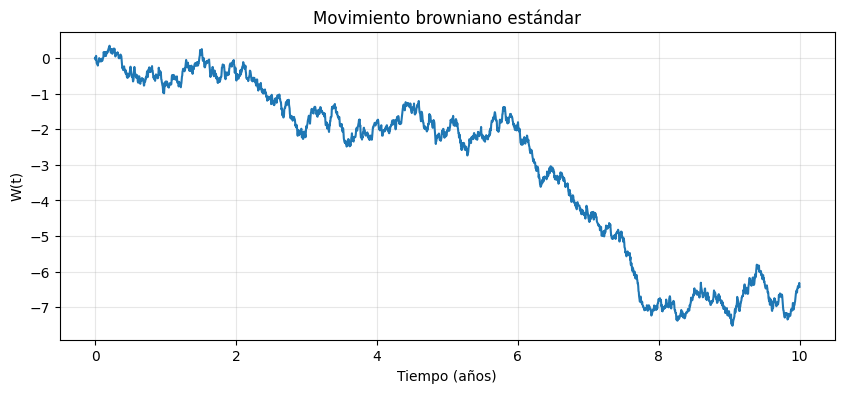

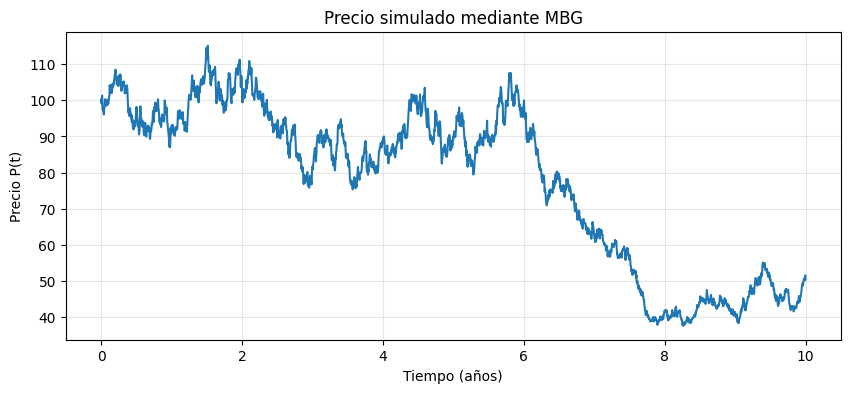

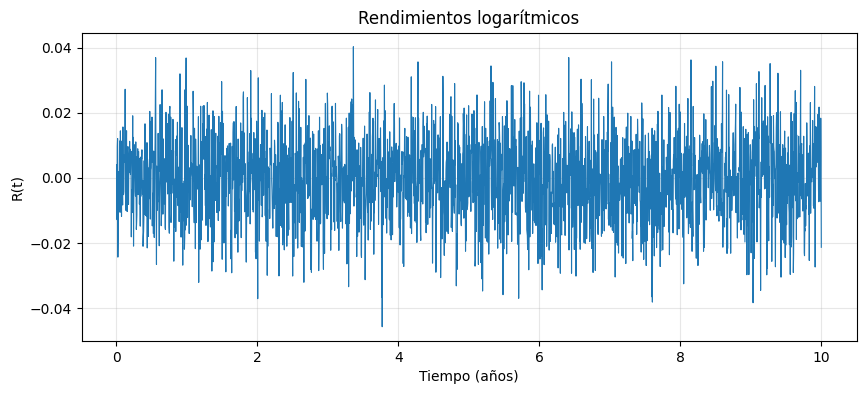

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(t, W)
plt.title("Movimiento browniano estándar")
plt.xlabel("Tiempo (años)")
plt.ylabel("W(t)")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t, P)
plt.title("Precio simulado mediante MBG")
plt.xlabel("Tiempo (años)")
plt.ylabel("Precio P(t)")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t[1:], R, linewidth=0.8)
plt.title("Rendimientos logarítmicos")
plt.xlabel("Tiempo (años)")
plt.ylabel("R(t)")
plt.grid(alpha=0.3)
plt.show()

## 8. Histograma y distribución normal teórica

Si el modelo es correcto, el histograma de los rendimientos debe aproximarse a la densidad normal con la media y desviación estándar teóricas.

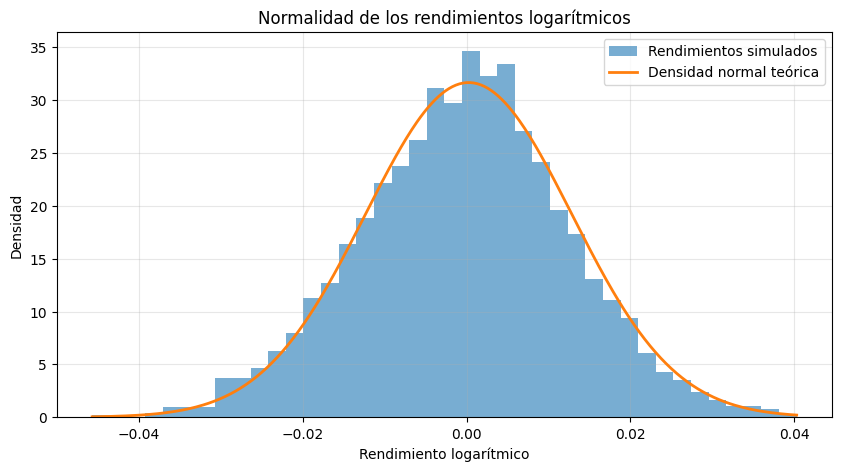

In [ ]:
x = np.linspace(min(R), max(R), 400)
densidad_teorica = stats.norm.pdf(x, loc=media_teorica, scale=desv_teorica)

plt.figure(figsize=(10, 5))
plt.hist(R, bins=40, density=True, alpha=0.6, label="Rendimientos simulados")
plt.plot(x, densidad_teorica, linewidth=2, label="Densidad normal teórica")
plt.title("Normalidad de los rendimientos logarítmicos")
plt.xlabel("Rendimiento logarítmico")
plt.ylabel("Densidad")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Gráfico Q-Q

Si la distribución es aproximadamente normal, los puntos seguirán la recta de referencia.

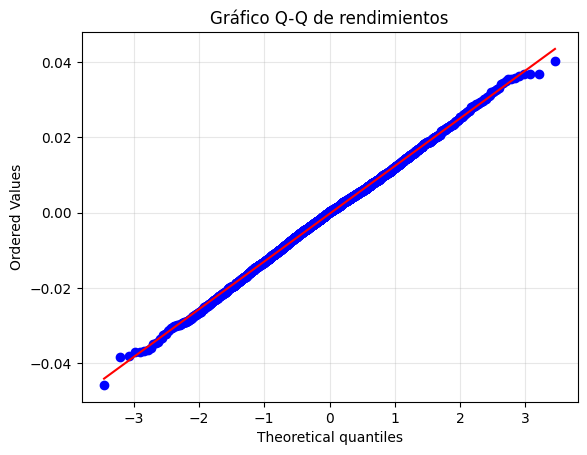

In [ ]:
stats.probplot(R, dist="norm", plot=plt)
plt.title("Gráfico Q-Q de rendimientos")
plt.grid(alpha=0.3)
plt.show()

## 10. Prueba de Kolmogorov-Smirnov

Contrastamos $H_0$: la distribución de $R_i$ es la normal **teórica** dada por el modelo. No estimamos parámetros con estos rendimientos para aplicar esta prueba.

In [ ]:
resultado_ks = stats.kstest(R, "norm", args=(media_teorica, desv_teorica))
print(f"Estadístico KS: {resultado_ks.statistic:.6f}")
print(f"Valor p: {resultado_ks.pvalue:.6f}")
if resultado_ks.pvalue > 0.05:
    print("Al 5%, no se rechaza la distribución normal teórica.")
else:
    print("Al 5%, se rechaza la distribución normal teórica.")
print("Nota: no rechazar H0 no prueba que la distribución sea exactamente normal.")

Estadístico KS: 0.023702
Valor p: 0.115988
Al 5%, no se rechaza la distribución normal teórica.
Nota: no rechazar H0 no prueba que la distribución sea exactamente normal.


## 11. Guardar los datos (opcional)

Se genera un archivo CSV con los precios y rendimientos simulados.

In [ ]:
resultados.to_csv("resultados_mbg.csv", index=False)
print("Archivo generado: resultados_mbg.csv")

Archivo generado: resultados_mbg.csv
